# Task 3: Dimensionality Reduction via Principal Component Analysis

## Step 1: Import libraries and configure plotting

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({"font.size": 9, "figure.dpi": 200})
results = {}

## Step 2: Load or generate data and fit the model

In [2]:
data = load_breast_cancer()
X3 = StandardScaler().fit_transform(data.data)   # 569 x 30, zero mean, unit variance
pca = PCA().fit(X3)                              # all 30 components
cum = np.cumsum(pca.explained_variance_ratio_)
n85 = int(np.argmax(cum >= 0.85) + 1)            # smallest k with >= 85% variance
Z = pca.transform(X3)[:, :2]                     # projection on PC1, PC2

## Step 3: Collect the assessment results

In [3]:
results["task3"] = {
    "n85": n85,
    "cum": cum.tolist(),
    "evr": pca.explained_variance_ratio_.tolist(),
    "n_malignant": int((data.target == 0).sum()),
    "n_benign": int((data.target == 1).sum()),
}

## Step 4: Display key numerical results

In [4]:
print(f"Tumours: {len(X3)} | malignant: {(data.target == 0).sum()} | benign: {(data.target == 1).sum()}")
print(f"Minimum PCs for >=85% variance: {n85}")
print(f"Variance with 5 PCs: {cum[4]:.8%}; with 6 PCs: {cum[5]:.8%}")
print("PC1, PC2 explained variance:", np.round(pca.explained_variance_ratio_[:2], 8))

Tumours: 569 | malignant: 212 | benign: 357
Minimum PCs for >=85% variance: 6
Variance with 5 PCs: 84.73427432%; with 6 PCs: 88.75879636%
PC1, PC2 explained variance: [0.44272026 0.18971182]


## Step 5: Show the main figure

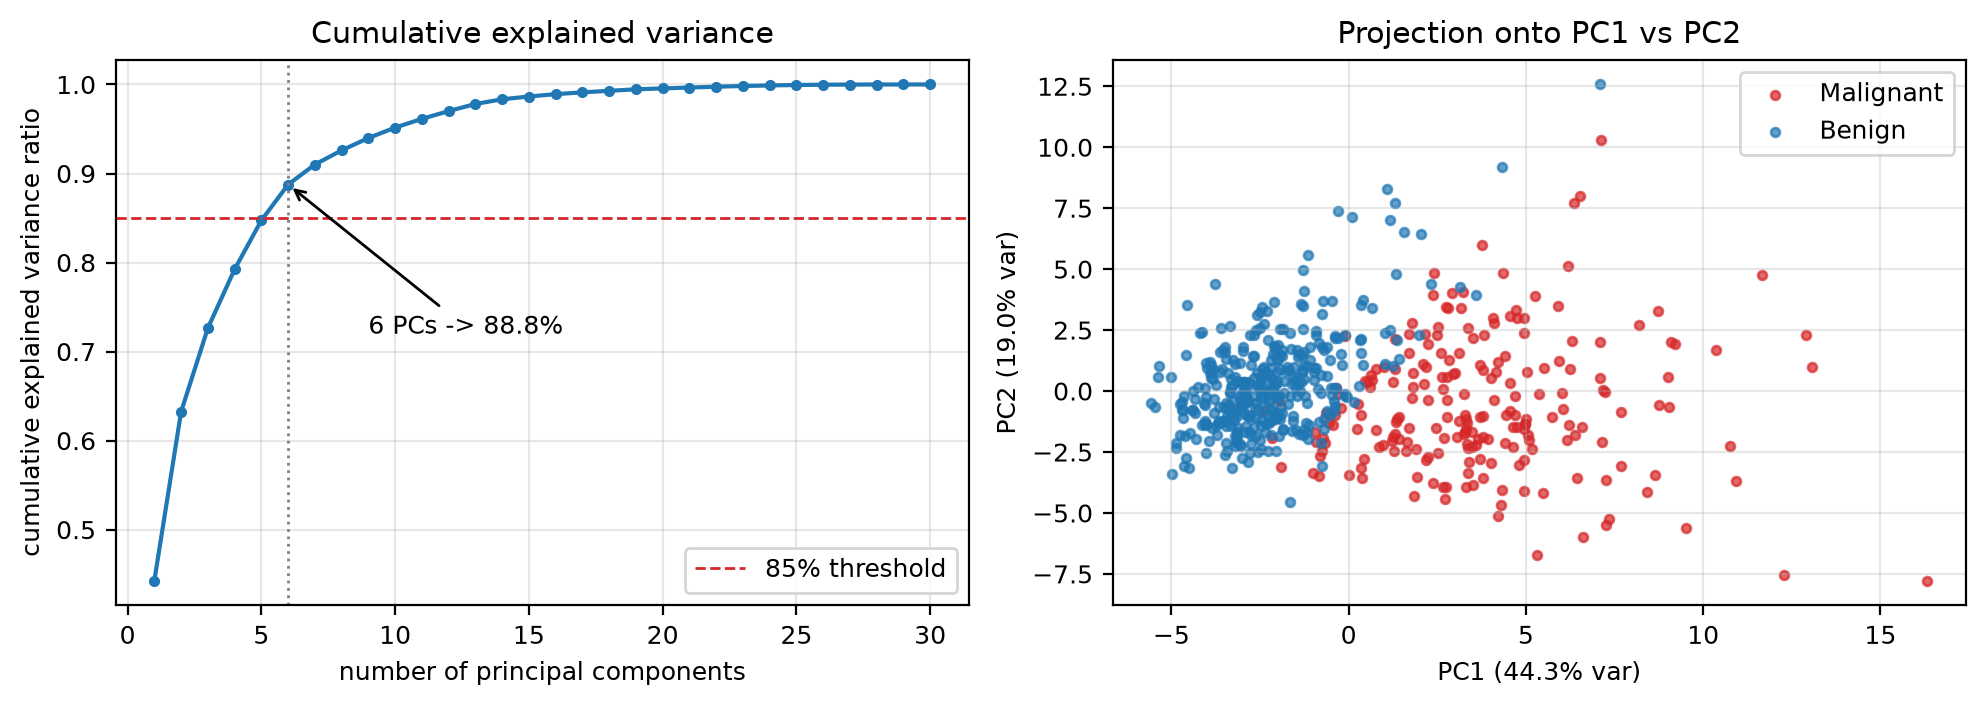

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
k = np.arange(1, len(cum) + 1)
axes[0].plot(k, cum, marker="o", ms=3)
axes[0].axhline(0.85, color="tab:red", ls="--", lw=1, label="85% threshold")
axes[0].axvline(n85, color="gray", ls=":", lw=1)
axes[0].annotate(f"{n85} PCs -> {cum[n85 - 1]:.1%}", (n85, cum[n85 - 1]), xytext=(n85 + 3, 0.72),
                 arrowprops={"arrowstyle": "->"})
axes[0].set_xlabel("number of principal components")
axes[0].set_ylabel("cumulative explained variance ratio")
axes[0].set_title("Cumulative explained variance")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)
for label, name, color in ((0, "Malignant", "tab:red"), (1, "Benign", "tab:blue")):
    m = data.target == label
    axes[1].scatter(Z[m, 0], Z[m, 1], s=10, alpha=0.7, label=name, color=color)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
axes[1].set_title("Projection onto PC1 vs PC2")
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Complete numeric results for reproducibility

In [6]:
print(json.dumps(results["task3"], sort_keys=True))

{"cum": [0.4427202560752637, 0.6324320765155946, 0.7263637090899084, 0.7923850582446099, 0.8473427431680726, 0.8875879635669061, 0.9100953006967311, 0.9259825386969444, 0.9398790324425355, 0.951568814336667, 0.9613660042126472, 0.970071383220026, 0.9781166330919933, 0.9833502905469196, 0.986488122714547, 0.9891502160796993, 0.9911301840050236, 0.99288414345525, 0.9945333965144751, 0.9955720432628138, 0.996571139726514, 0.9974857864775684, 0.9982971477364675, 0.9988989813031391, 0.9994150236823043, 0.9996876116777818, 0.9999176271402878, 0.9999706050693259, 0.9999955651725728, 1.0], "evr": [0.4427202560752637, 0.18971182044033086, 0.09393163257431376, 0.06602134915470147, 0.05495768492346267, 0.04024522039883345, 0.02250733712982505, 0.015887238000213296, 0.013896493745591092, 0.011689781894131517, 0.0097971898759802, 0.008705379007378826, 0.008045249871967317, 0.005233657454926348, 0.003137832167627382, 0.0026620933651523055, 0.0019799679253242886, 0.001753959450226368, 0.0016492530592